# RUL Prediction — Phase 1, Notebook 1
## C-MAPSS FD001: Data Loading & Exploratory Analysis

**Dissertation:** Deep Learning-Based Remaining Useful Life Prediction for Industrial Rotating Equipment
**Author:** K Vatsav Sai Ram · BITS ID 2024TM05021 · M.Tech (AI & ML)

---

### What this notebook does
This is the **first building block** of the project. Before any model, we need to *understand the data*.
By the end of this notebook we will have:

1. Loaded the raw C-MAPSS FD001 files and given the columns proper names.
2. Understood the structure — engines, cycles, operating settings, sensors.
3. Explored how long engines run and how sensors behave over an engine's life.
4. Identified which sensors are **informative** (trend toward failure) vs **useless** (flat/constant).

We are starting with **FD001** — the simplest subset: **1 operating condition, 1 fault mode**.
Get the full pipeline working end-to-end here, then extend to FD002–FD004 later.


## 1. Setup

Standard scientific-Python stack. We fix a random seed so every run is reproducible — important for a dissertation where results must be repeatable.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
pd.set_option("display.max_columns", 40)

# --- project paths: Colab+Drive if available, else a local folder ---
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = "/content/drive/MyDrive/RUL_Dissertation"
except ImportError:
    PROJECT_DIR = os.path.abspath(".")

DATA_DIR     = os.path.join(PROJECT_DIR, "data", "cmapss")
ARTIFACT_DIR = os.path.join(PROJECT_DIR, "artifacts")
PROC_DIR     = os.path.join(PROJECT_DIR, "processed")
MODEL_DIR    = os.path.join(PROJECT_DIR, "models")
for _d in (ARTIFACT_DIR, PROC_DIR, MODEL_DIR):
    os.makedirs(_d, exist_ok=True)
assert os.path.isdir(DATA_DIR), f"Place the C-MAPSS .txt files in {DATA_DIR}"
print("DATA_DIR:", DATA_DIR)

## 2. Understanding the raw file format

The C-MAPSS files are **space-separated text with no header row**. Every row is one *operating cycle*
of one *engine*, and the columns are always in this fixed order:

| Position | Meaning |
|---|---|
| 1 | `unit` — engine number (1, 2, 3, …). Each engine is an independent run-to-failure trajectory. |
| 2 | `cycle` — time index for that engine (1, 2, 3, … until it fails). |
| 3–5 | `op_setting_1..3` — the three operational settings that define the flight/operating condition. |
| 6–26 | `sensor_1..21` — the 21 sensor measurements (temperatures, pressures, speeds, flows, …). |

**Key idea for RUL:** in the *training* data every engine runs **until it fails**, so the last cycle of an
engine = the moment of failure. In the *test* data each engine's record **stops early**, and our job is to
predict how many cycles it has left — the ground truth is in the separate `RUL_FD001.txt`.

In [2]:
# Build the column names in the exact fixed order of the files
index_cols = ["unit", "cycle"]
setting_cols = [f"op_setting_{i}" for i in range(1, 4)]
sensor_cols  = [f"sensor_{i}" for i in range(1, 22)]
all_cols = index_cols + setting_cols + sensor_cols

print(f"Total columns: {len(all_cols)}  (2 index + 3 settings + 21 sensors)")
print(all_cols)

Total columns: 26  (2 index + 3 settings + 21 sensors)
['unit', 'cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


## 3. Load the data

We read the space-separated files. There is a trailing space on each line in the original files,
which pandas reads as two extra empty columns — we handle that by using `sep=r'\s+'` (split on any
run of whitespace) which cleanly ignores it.

In [3]:
def load_cmapss(split):
    """split is 'train' or 'test'. Returns a DataFrame with named columns."""
    path = f"{DATA_DIR}/{split}_FD001.txt"
    df = pd.read_csv(path, sep=r"\s+", header=None, names=all_cols)
    return df

train = load_cmapss("train")
test  = load_cmapss("test")

# Ground-truth RUL for the test engines (one value per engine, in engine order)
rul_truth = pd.read_csv(f"{DATA_DIR}/RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL"])

print("train shape:", train.shape)
print("test  shape:", test.shape)
print("rul_truth shape:", rul_truth.shape)
train.head()

train shape: (20631, 26)
test  shape: (13096, 26)
rul_truth shape: (100, 1)


,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 4. Basic structure — how many engines, how long do they run?

Let's confirm our mental model: how many engines are in the training set, and how many cycles
does each run before failing? The spread of engine lifetimes tells us a lot about the problem.

In [4]:
n_engines_train = train["unit"].nunique()
n_engines_test  = test["unit"].nunique()
print(f"Training engines: {n_engines_train}")
print(f"Test engines:     {n_engines_test}")

# lifetime (max cycle) of each training engine
life = train.groupby("unit")["cycle"].max()
print("\nTraining engine lifetime (cycles):")
print(life.describe()[["min", "25%", "50%", "75%", "max", "mean"]].round(1))

Training engines: 100
Test engines:     100

Training engine lifetime (cycles):
min     128.0
25%     177.0
50%     199.0
75%     229.2
max     362.0
mean    206.3
Name: cycle, dtype: float64


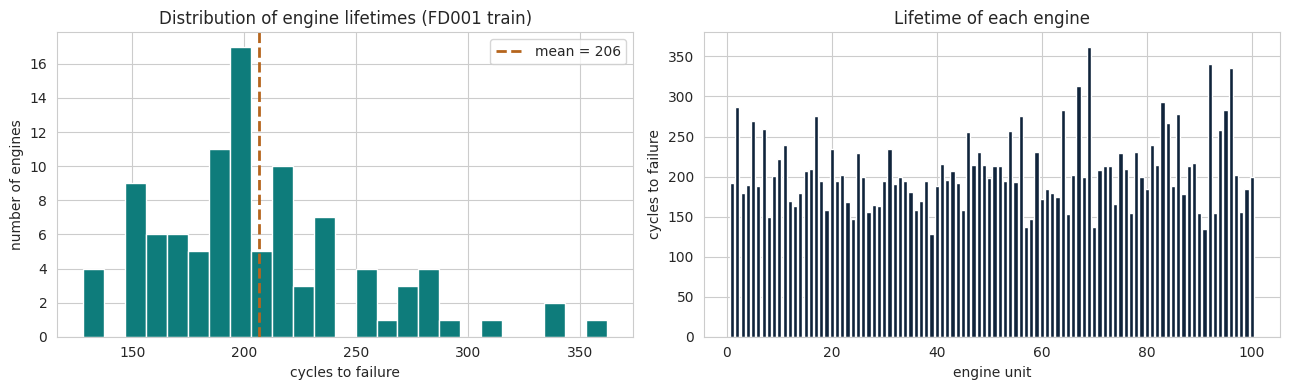

Shortest-lived engine: 128 cycles | Longest-lived: 362 cycles
Takeaway: engines fail at very different ages — the model must infer health from SENSORS, not age.


In [5]:
# Visualise the distribution of engine lifetimes
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(life, bins=25, color="#0E7C7B", edgecolor="white")
ax[0].axvline(life.mean(), color="#B5651D", ls="--", lw=2, label=f"mean = {life.mean():.0f}")
ax[0].set_title("Distribution of engine lifetimes (FD001 train)")
ax[0].set_xlabel("cycles to failure"); ax[0].set_ylabel("number of engines"); ax[0].legend()

ax[1].bar(life.index, life.values, color="#10243B")
ax[1].set_title("Lifetime of each engine")
ax[1].set_xlabel("engine unit"); ax[1].set_ylabel("cycles to failure")
plt.tight_layout(); plt.show()

print(f"Shortest-lived engine: {life.min()} cycles | Longest-lived: {life.max()} cycles")
print("Takeaway: engines fail at very different ages — the model must infer health from SENSORS, not age.")

## 5. Operating settings — confirming FD001 is single-condition

FD001 is documented as having **one operating condition**. Let's verify: the three operating settings
should barely vary (all operation happens at essentially one regime). This matters because in the
harder subsets (FD002/FD004) these settings take six distinct clusters, which forces
*condition-specific normalisation* later. Confirming it here builds the intuition.

In [6]:
print("Operating-setting ranges in FD001:")
print(train[setting_cols].describe().loc[["min", "max", "std"]].round(3))
print()
print("The settings vary only slightly (small std) -> effectively ONE operating condition.")
print("This is why FD001 is the simplest subset to start with.")

Operating-setting ranges in FD001:
     op_setting_1  op_setting_2  op_setting_3
min        -0.009        -0.001         100.0
max         0.009         0.001         100.0
std         0.002         0.000           0.0

The settings vary only slightly (small std) -> effectively ONE operating condition.
This is why FD001 is the simplest subset to start with.


## 6. Sensor behaviour over an engine's life

This is the heart of the EDA. For a *degradation* problem, a useful sensor is one whose value
**drifts as the engine ages** — that drift is the fingerprint of wear. A sensor that stays flat
carries no degradation information and should be dropped.

Let's plot every sensor against cycle for a few engines and see which ones trend.

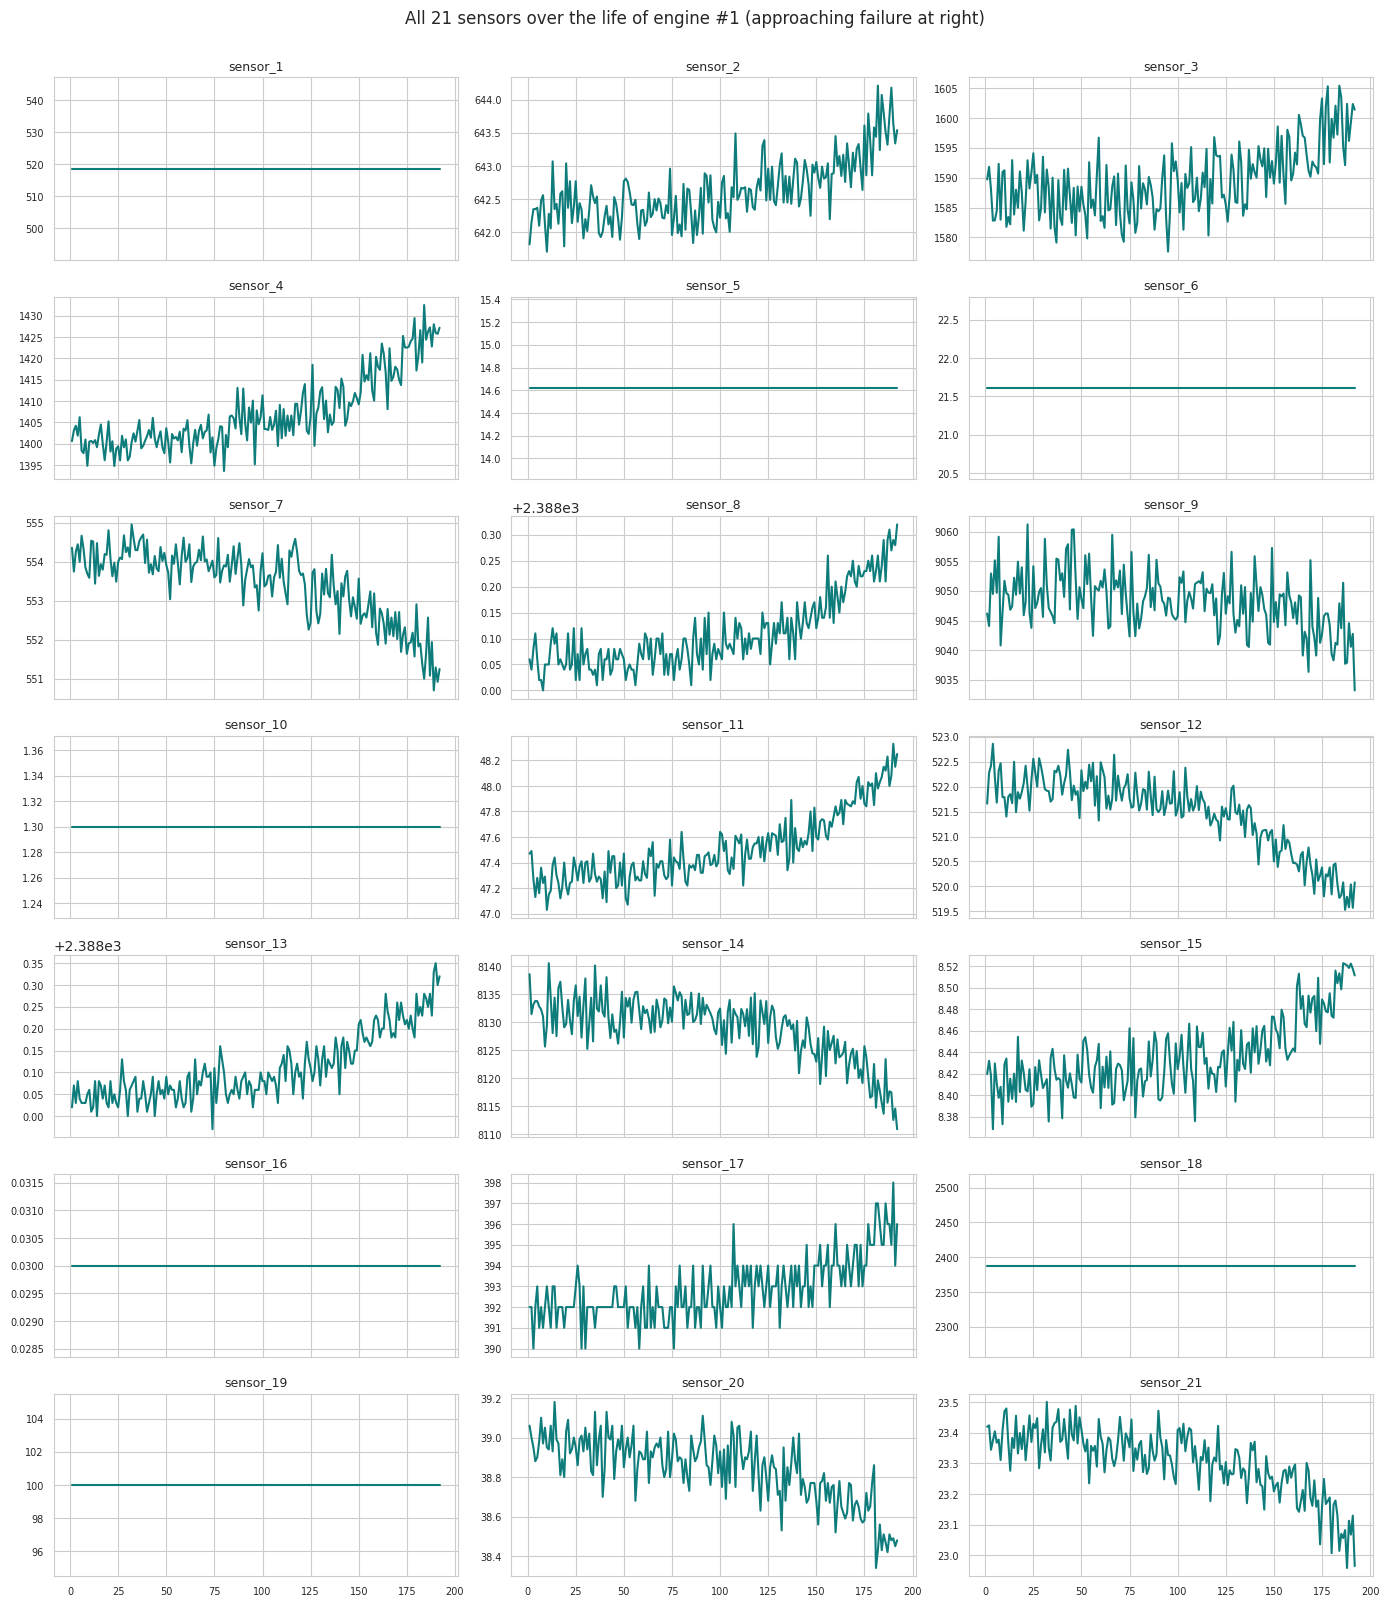

In [7]:
# Plot all 21 sensors for one representative engine (unit 1)
u = 1
eng = train[train["unit"] == u]

fig, axes = plt.subplots(7, 3, figsize=(14, 16), sharex=True)
for i, s in enumerate(sensor_cols):
    ax = axes[i // 3, i % 3]
    ax.plot(eng["cycle"], eng[s], color="#0E7C7B")
    ax.set_title(s, fontsize=9)
    ax.tick_params(labelsize=7)
fig.suptitle(f"All 21 sensors over the life of engine #{u} (approaching failure at right)", y=1.001, fontsize=12)
plt.tight_layout(); plt.show()

Notice two clear groups already:

- **Flat lines** (e.g. sensors 1, 5, 10, 16, 18, 19) — constant the whole life → **no information**.
- **Trending lines** (rising or falling toward the end) — these track degradation → **keep these**.

Let's identify the flat sensors quantitatively rather than by eye.

In [8]:
# A sensor with (near) zero variance across the whole dataset is useless.
sensor_std = train[sensor_cols].std().sort_values()
print("Sensor standard deviations (ascending):")
print(sensor_std.round(4))

# Flag effectively-constant sensors
flat_sensors = sensor_std[sensor_std < 1e-6].index.tolist()
print(f"\nEffectively CONSTANT sensors (std ~ 0): {flat_sensors}")

Sensor standard deviations (ascending):
sensor_1      0.0000
sensor_10     0.0000
sensor_19     0.0000
sensor_18     0.0000
sensor_16     0.0000
sensor_5      0.0000
sensor_6      0.0014
sensor_15     0.0375
sensor_8      0.0710
sensor_13     0.0719
sensor_21     0.1083
sensor_20     0.1807
sensor_11     0.2671
sensor_2      0.5001
sensor_12     0.7376
sensor_7      0.8851
sensor_17     1.5488
sensor_3      6.1311
sensor_4      9.0006
sensor_14    19.0762
sensor_9     22.0829
dtype: float64

Effectively CONSTANT sensors (std ~ 0): ['sensor_1', 'sensor_10', 'sensor_19', 'sensor_18', 'sensor_16', 'sensor_5']


In [9]:
# Some sensors aren't perfectly flat but are still non-informative (tiny discrete steps, no trend).
# The community-standard set of NON-informative sensors for FD001 is: 1, 5, 6, 10, 16, 18, 19.
# We'll confirm our data-driven flat list is consistent with that and define the sensors to KEEP.
standard_drop = ["sensor_1","sensor_5","sensor_6","sensor_10","sensor_16","sensor_18","sensor_19"]
keep_sensors = [s for s in sensor_cols if s not in standard_drop]

print(f"Dropping {len(standard_drop)} non-informative sensors: {standard_drop}")
print(f"\nKeeping {len(keep_sensors)} informative sensors:")
print(keep_sensors)

Dropping 7 non-informative sensors: ['sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']

Keeping 14 informative sensors:
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


## 7. A closer look at the informative sensors

Let's overlay several engines for a few of the *kept* sensors. Two things should stand out:
1. The sensors show a **consistent trend direction** across engines as they approach failure.
2. Engines are noisy and start at slightly different points (unknown initial wear) — which is exactly
   why a **sequence model** (LSTM) that looks at a *window* of recent cycles will beat a single-cycle guess.

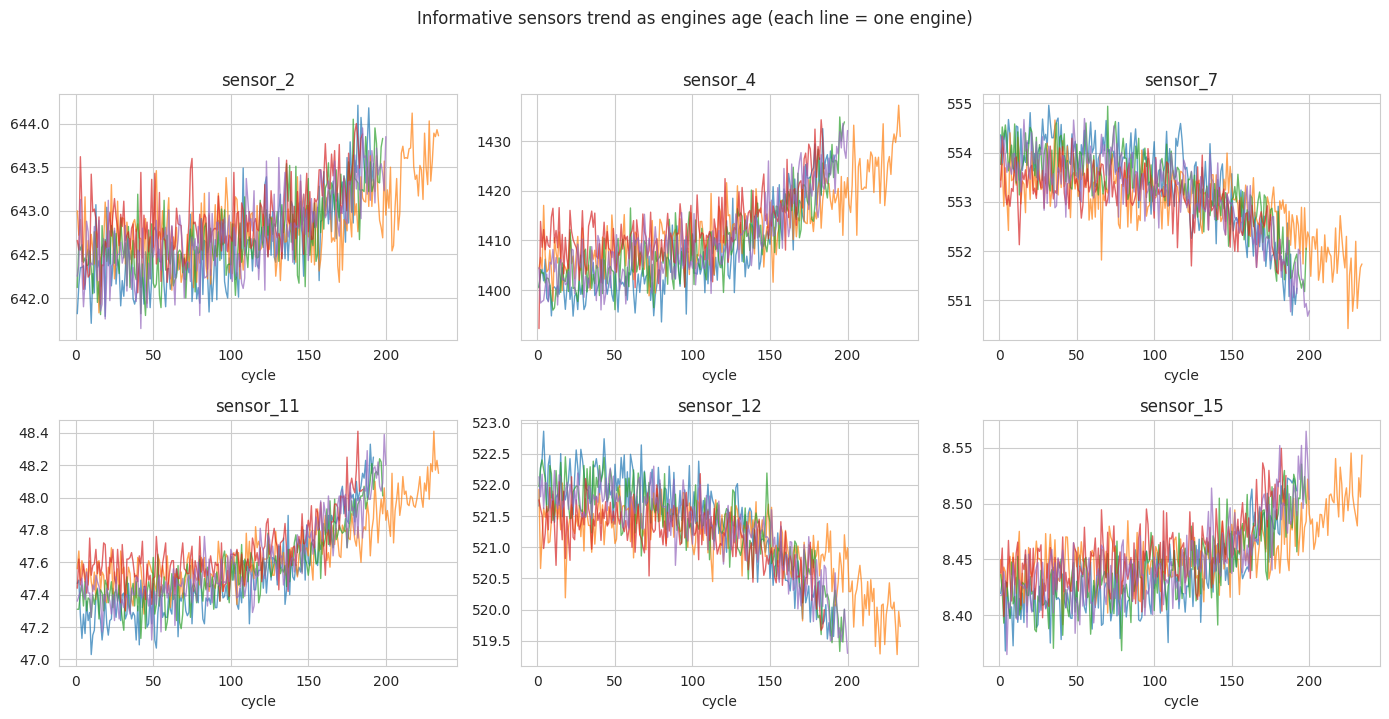

These sensors clearly drift toward failure -> they carry the degradation signal the model will learn.


In [10]:
example_sensors = ["sensor_2", "sensor_4", "sensor_7", "sensor_11", "sensor_12", "sensor_15"]
some_engines = [1, 20, 50, 80, 100]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, s in zip(axes.ravel(), example_sensors):
    for e in some_engines:
        d = train[train["unit"] == e]
        ax.plot(d["cycle"], d[s], alpha=0.7, lw=1)
    ax.set_title(s); ax.set_xlabel("cycle")
fig.suptitle("Informative sensors trend as engines age (each line = one engine)", y=1.02)
plt.tight_layout(); plt.show()

print("These sensors clearly drift toward failure -> they carry the degradation signal the model will learn.")

## 8. Correlation between kept sensors

Some sensors move together (physically related measurements). This isn't a problem for an LSTM,
but it's useful to *know* — and it's the kind of insight SHAP will later confirm from the model's side.

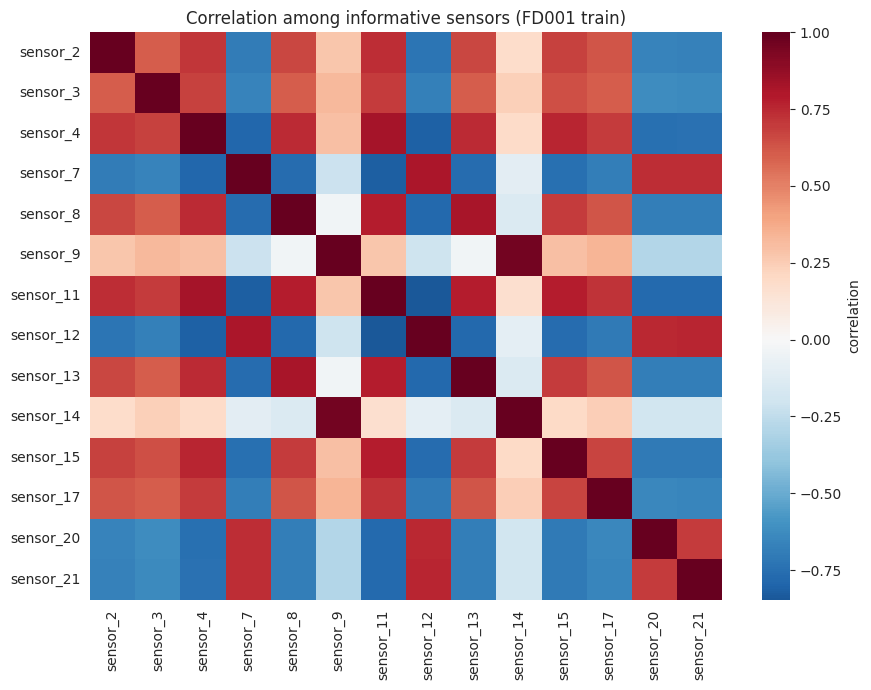

In [11]:
corr = train[keep_sensors].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=False, cbar_kws={"label": "correlation"})
plt.title("Correlation among informative sensors (FD001 train)")
plt.tight_layout(); plt.show()

## 9. Summary & what we carry forward

**What we established in this notebook:**

- FD001 has **100 training engines** (run to failure) and **100 test engines** (truncated early), single operating condition.
- Engine lifetimes vary widely (~128 to ~360 cycles) — so **age alone can't predict failure**; the model must read the sensors.
- **7 sensors are non-informative** (`1,5,6,10,16,18,19`) and are dropped; **14 sensors are kept**.
- The kept sensors show clear degradation trends, which is what the LSTM will learn from.

**Next notebook (Step 2 — Preprocessing):**
1. Compute the **RUL label** for every training row (piecewise-linear, capped at 125).
2. **Normalise** the kept sensors (min-max scaling, fit on train only).
3. Build **sliding-window sequences** (the input format an LSTM needs).
4. Prepare the test set so each engine yields one sequence for its final RUL prediction.

We save the cleaned config so the next notebook reuses exactly these choices.

In [ ]:
import json
config = {
    "subset": "FD001",
    "index_cols": index_cols,
    "setting_cols": setting_cols,
    "sensor_cols": sensor_cols,
    "drop_sensors": standard_drop,
    "keep_sensors": keep_sensors,
    "rul_cap": 125,          # piecewise-linear RUL clip (standard for C-MAPSS)
    "seed": SEED,
}
cfg_path = os.path.join(ARTIFACT_DIR, "config_FD001.json")
with open(cfg_path, "w") as f:
    json.dump(config, f, indent=2)
print("Saved", cfg_path)
print(json.dumps(config, indent=2))